# Introducción a Tensorflow 2


In [13]:
import tensorflow as tf
import time
print(tf.__version__)


2.21.0


## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [17]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
y_train = y_train % 2
y_test = y_test % 2

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [18]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [1 0 0 1 1]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [19]:
# Usar semillas para poder reproducir el resultado del experimento
tf.keras.utils.set_random_seed(42)

x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype


dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [20]:
# Fijamos semilla para inicializar siempre con los mismos pesos
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])


/home/albertogc/Documentos/Uni/4_1Cuatri/APRENDIZAJE/P1/.venv/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [21]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [22]:
h=model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9549 - loss: 0.1210
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9810 - loss: 0.0561
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9868 - loss: 0.0398
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9905 - loss: 0.0298
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9929 - loss: 0.0225


## Evaluación
Una vez entrenada la red neuronal, prodremos obtener las medidas de rendimiento espcificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [23]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9944 - loss: 0.0178
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9847 - loss: 0.0437


[0.04373596981167793, 0.9847000241279602]

---
## Función de Evaluación Detallada
Esta función calcula y muestra:
- **Exactitud (Accuracy)** en Train y Test.
- **Número total de errores** (clasificaciones incorrectas) en Train y Test.
- **Matrices de confusión gráficas** para analizar qué dígitos se confunden más.
- **Tiempo invertido en el entrenamiento** (en segundos).

In [24]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_seg=None):
    """
    Calcula exactitud, número de errores, matriz de confusión en train y test,
    y muestra el tiempo invertido en el entrenamiento (adaptado para clasificación binaria).
    """
    # 1. Obtener predicciones binarias (umbral 0.5)
    y_pred_prob_train = model.predict(x_train, verbose=0)
    y_pred_train = (y_pred_prob_train >= 0.5).astype(int).reshape(-1)
    
    y_pred_prob_test = model.predict(x_test, verbose=0)
    y_pred_test = (y_pred_prob_test >= 0.5).astype(int).reshape(-1)
    
    # 2. Número de errores y exactitud
    err_train = int(np.sum(y_pred_train != y_train))
    acc_train = (1.0 - (err_train / len(y_train))) * 100
    
    err_test = int(np.sum(y_pred_test != y_test))
    acc_test = (1.0 - (err_test / len(y_test))) * 100
    
    # 3. Mostrar resumen detallado
    print("=" * 62)
    print("             RESULTADOS DE LA EVALUACIÓN DETALLADA")
    print("=" * 62)
    if tiempo_seg is not None:
        print(f"⏱️  Tiempo de entrenamiento : {tiempo_seg:.2f} segundos")
    print(f"🏋️  Entrenamiento (Train)   : Exactitud = {acc_train:.2f}% | Errores = {err_train} / {len(y_train)}")
    print(f"🧪  Prueba (Test)           : Exactitud = {acc_test:.2f}% | Errores = {err_test} / {len(y_test)}")
    print("=" * 62)
    
    # 4. Matrices de confusión
    cm_train = confusion_matrix(y_train, y_pred_train)
    cm_test = confusion_matrix(y_test, y_pred_test)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=['Par (0)', 'Impar (1)']).plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f"Matriz de Confusión - Train ({err_train} errores)")
    
    ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['Par (0)', 'Impar (1)']).plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title(f"Matriz de Confusión - Test ({err_test} errores)")
    
    plt.tight_layout()
    plt.show()
    
    return {
        "tiempo": tiempo_seg,
        "acc_train": acc_train, "err_train": err_train,
        "acc_test": acc_test, "err_test": err_test,
        "cm_train": cm_train, "cm_test": cm_test
    }


---
## Experimento 1

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9593 - loss: 0.1089
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9830 - loss: 0.0503
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9884 - loss: 0.0345
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9922 - loss: 0.0242
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9948 - loss: 0.0166
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9965 - loss: 0.0126
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9970 - loss: 0.0099
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9975 - loss: 0.0083
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9980 - loss: 0.0068
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9980 - loss: 0.0059
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9983 - loss: 0.0054
Epoch 12/20
1875/1875 ━━━━━━━━

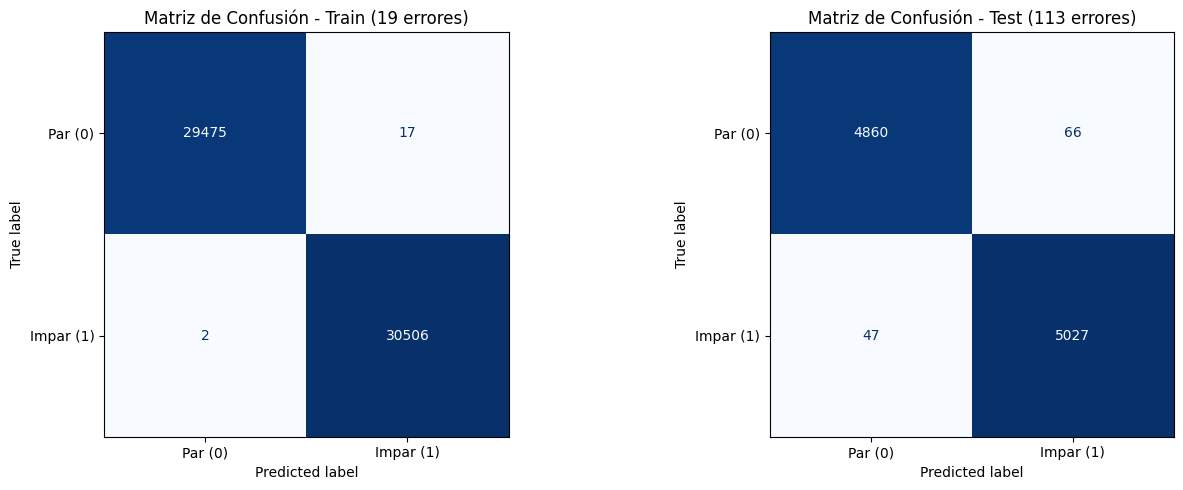

In [ ]:
import time
# --- EXPERIMENTO 1

# 0. Fijamos semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# 1. Definición del modelo (reinicio de pesos)
model_exp1 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

# 2. Compilación
model_exp1.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

# 3. Entrenamiento (midiendo el tiempo)
t_inicio = time.time()
h_exp1 = model_exp1.fit(x_train, y_train,
                        epochs=20,
                        batch_size=None,
                        validation_split=0.0)
t_exp1 = time.time() - t_inicio

# 4. Evaluación detallada (exactitud, errores, matriz de confusión y tiempo)
res_exp1 = evaluar_modelo(model_exp1, x_train, y_train, x_test, y_test, tiempo_seg=t_exp1)


---
## Experimento 2

/home/albertogc/Documentos/Uni/4_1Cuatri/APRENDIZAJE/P1/.venv/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9577 - loss: 0.1128
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9803 - loss: 0.0570
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9852 - loss: 0.0436
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9883 - loss: 0.0341
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9892 - loss: 0.0301
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9913 - loss: 0.0255
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9920 - loss: 0.0225
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9929 - loss: 0.0197
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9933 - loss: 0.0185
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9941 - loss: 0.0173
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9949 - loss: 0.0153
Epoch 12/20
1875/1875 ━━━━━━━

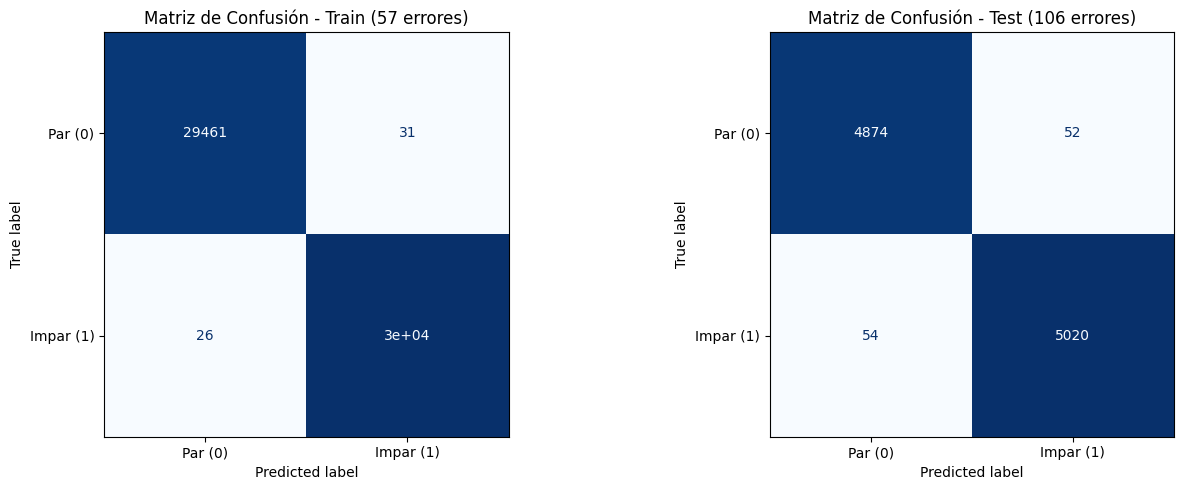

In [ ]:
import time
# --- EXPERIMENTO 2

# 0. Fijamos semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# 1. Definición del modelo (reinicio de pesos)
model_exp2 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dropout(0.2), # <-- Desactiva el 20% de neuronas al entrenar
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2), # <-- Desactiva el 20% de neuronas al entrenar
  tf.keras.layers.Dense(1, activation='sigmoid')
])


# 2. Compilación
model_exp2.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

# 3. Entrenamiento (midiendo el tiempo)
t_inicio = time.time()
h_exp2 = model_exp2.fit(x_train, y_train,
                        epochs=20,
                        batch_size=None,
                        validation_split=0.0)
t_exp2 = time.time() - t_inicio

# 4. Evaluación detallada (exactitud, errores, matriz de confusión y tiempo)
res_exp2 = evaluar_modelo(model_exp2, x_train, y_train, x_test, y_test, tiempo_seg=t_exp2)


---
## Conclusiones Finales y Elección del Mejor Modelo

### 1. ¿Cuál ha sido el mejor modelo?
El modelo que ha obtenido el mejor rendimiento en los datos de test ha sido el del Experimento 2, en el que usamos dropout, aunque es muy similar al experimento 1.

---
### 2. Justificación de los resultados y parámetros probados

He usados un número alto de neuronas, pues he comprobado que ayuda a mejorar el modelo significativamente al aumentar su capacidad de aprendizaje, no he realizado muchas 
pruebas con diferebtes parámetros porque como podemos ver es casi imposible conseguir un mejor resultado debido a las propias ambiguedades de los números y el riesgo de 
sobreentrenamiento de la red.

---
### 3. Análisis de la Matriz de Confusión
Al mirar las matrices de confusión, los errores más comunes se dan entre números que se parecen visualmente al escribirlos a mano:
- El 9 se confunde principalmente con el 4 y el 7 (por compartir la línea vertical y el trazo superior).
- El 8 se confunde con el 3 y el 5.
- El 7 se confunde a veces con el 2.


In [31]:
# --- GUARDAR EL MEJOR MODELO EN DISCO ---
# Asignamos el mejor modelo obtenido (Experimento 1: 512 neuronas)
mejor_modelo = model_exp2

# Guardamos el modelo en formato nativo de Keras (.keras)
nombre_archivo = 'mejor_modelo_mnist.keras'
mejor_modelo.save(nombre_archivo)
print(f"Mejor modelo guardado en disco como '{nombre_archivo}'")

# Verificación: recargamos el modelo desde disco y evaluamos en Test
modelo_cargado = tf.keras.models.load_model(nombre_archivo)
perdida, exactitud = modelo_cargado.evaluate(x_test, y_test, verbose=0)
print(f"Verificación del modelo cargado en Test: Exactitud = {exactitud * 100:.2f}%")


Mejor modelo guardado en disco como 'mejor_modelo_mnist.keras'
Verificación del modelo cargado en Test: Exactitud = 98.94%
